# Sumativa 3 — Parte 4: impacto de la estrategia de imputación

Esta sección ajusta **el modelo logístico final de la Parte 2** bajo eliminación, imputación simple e imputación por regresión. Se comparan tamaño muestral, coeficientes, intervalos de confianza, AUC, accuracy y recall en prueba. No selecciona variables ni reemplaza el trabajo de modelamiento del grupo; solamente mide si el tratamiento de faltantes modifica sus conclusiones.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
)

from utils_s3 import (
    OBJETIVO, NOMBRES, NUMERICAS, cargar_datos, preparar_particiones_por_estrategia, preparar_modelo, ajustar_logit, predecir
)

BASE = Path('.')
TABLAS = BASE / 'tablas'
FIGURAS = BASE / 'figuras'
TABLAS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

## 4.1 Especificación común y prevención de fuga

La especificación se lee de `config_modelo_final.json`, que escribe la Parte 2: mismas variables, misma estandarización (`preparar_modelo`) y mismo ajuste (`ajustar_logit` con ponderación de clases y errores estándar robustos HC0). Así las tres estrategias se comparan sobre el modelo final y no sobre una versión simplificada.

La división 70/30 se realiza **antes** de imputar. Medianas, modas y regresiones se aprenden exclusivamente en entrenamiento y se aplican después a prueba. Esto cumple la recomendación metodológica de S2 y evita fuga de información.

In [2]:
config = json.loads((BASE / 'config_modelo_final.json').read_text(encoding='utf-8'))
VARIABLES_MODELO_FINAL = config['variables']
UMBRAL = config['umbral']
print('Variables:', VARIABLES_MODELO_FINAL)
print('Fuente:', config['fuente'], '| ajuste:', config['ajuste'])

Variables: ['age', 'male', 'sysBP', 'prevalentHyp', 'cigsPerDay', 'glucose']
Fuente: 02_modelos_logisticos.ipynb | ajuste: utils_s3.ajustar_logit(X, y, ponderar=True)


In [3]:
original = cargar_datos()
particiones, diagnosticos, conteos_train, conteos_test = preparar_particiones_por_estrategia(original)

metricas = []
coeficientes = []
curvas = []
for estrategia, (train, test) in particiones.items():
    X_train, X_test, y_train, y_test = preparar_modelo(train, test, VARIABLES_MODELO_FINAL)
    modelo = ajustar_logit(X_train, y_train, ponderar=True)
    probabilidades = predecir(modelo, X_test)
    predichos = (probabilidades >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predichos, labels=[0, 1]).ravel()
    intervalos = modelo.conf_int()
    metricas.append({
        'estrategia': estrategia,
        'n_total': len(train) + len(test),
        'n_train': len(train),
        'n_test': len(test),
        'eventos_train': int(y_train.sum()),
        'eventos_test': int(y_test.sum()),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'accuracy': accuracy_score(y_test, predichos),
        'precision': precision_score(y_test, predichos, zero_division=0),
        'recall': recall_score(y_test, predichos, zero_division=0),
        'F1': f1_score(y_test, predichos, zero_division=0),
        'AUC': roc_auc_score(y_test, probabilidades),
        'ancho_IC_medio': (intervalos[1] - intervalos[0])[VARIABLES_MODELO_FINAL].mean(),
    })
    coeficientes.append(pd.DataFrame({
        'estrategia': estrategia,
        'variable': modelo.params.index,
        'coeficiente': modelo.params.values,
        'IC95_inf': intervalos[0].values,
        'IC95_sup': intervalos[1].values,
        'odds_ratio': np.exp(modelo.params.values),
        'IC95_OR_inf': np.exp(intervalos[0].values),
        'IC95_OR_sup': np.exp(intervalos[1].values),
        'p_valor': modelo.pvalues.values,
    }))
    curvas.append((estrategia, y_test.to_numpy(), np.asarray(probabilidades)))

metricas = pd.DataFrame(metricas)
coeficientes = pd.concat(coeficientes, ignore_index=True)
metricas.to_csv(TABLAS / 'p4_impacto_imputacion_metricas.csv', index=False)
coeficientes.to_csv(TABLAS / 'p4_impacto_imputacion_coeficientes.csv', index=False)
display(metricas.style.format({
    'accuracy': '{:.3f}', 'precision': '{:.3f}', 'recall': '{:.3f}',
    'F1': '{:.3f}', 'AUC': '{:.3f}', 'ancho_IC_medio': '{:.3f}'
}))
display(coeficientes.style.format({
    'coeficiente': '{:.3f}', 'IC95_inf': '{:.3f}', 'IC95_sup': '{:.3f}',
    'odds_ratio': '{:.3f}', 'IC95_OR_inf': '{:.3f}',
    'IC95_OR_sup': '{:.3f}', 'p_valor': '{:.3g}'
}))

,estrategia,n_total,n_train,n_test,eventos_train,eventos_test,TN,FP,FN,TP,accuracy,precision,recall,F1,AUC,ancho_IC_medio
0,eliminacion,3658,2547,1111,392,165,661,285,62,103,0.688,0.265,0.624,0.373,0.711,0.369
1,simple,4240,2968,1272,451,193,745,334,72,121,0.681,0.266,0.627,0.373,0.708,0.338
2,regresion,4240,2968,1272,451,193,744,335,71,122,0.681,0.267,0.632,0.375,0.708,0.340


,estrategia,variable,coeficiente,IC95_inf,IC95_sup,odds_ratio,IC95_OR_inf,IC95_OR_sup,p_valor
0,eliminacion,const,-0.559,-0.775,-0.343,0.572,0.461,0.710,3.96e-07
1,eliminacion,age,0.669,0.539,0.799,1.952,1.714,2.223,7.58e-24
2,eliminacion,male,0.464,0.202,0.725,1.590,1.224,2.064,0.000505
3,eliminacion,sysBP,0.335,0.174,0.495,1.397,1.191,1.640,4.22e-05
4,eliminacion,prevalentHyp,0.185,-0.153,0.523,1.203,0.858,1.687,0.284
5,eliminacion,cigsPerDay,0.287,0.163,0.410,1.332,1.178,1.506,5e-06
6,eliminacion,glucose,0.163,0.068,0.258,1.177,1.070,1.295,0.000819
7,simple,const,-0.519,-0.716,-0.322,0.595,0.489,0.725,2.47e-07
8,simple,age,0.653,0.534,0.773,1.922,1.705,2.166,8.83e-27
9,simple,male,0.386,0.147,0.626,1.471,1.158,1.870,0.00159


Los predictores continuos se estandarizan con media y desviación estándar de cada entrenamiento. Por tanto, sus odds ratios representan un incremento de una desviación estándar y son comparables entre estrategias. Las variables binarias conservan su escala 0/1. Los pesos de clase se recalculan en cada entrenamiento con la misma regla de la Parte 2, n / (2 · n_clase). El umbral 0,5 se mantiene fijo para que accuracy, recall y matriz de confusión respondan solo al cambio de datos y no a diferentes reglas de clasificación.

In [4]:
coef_sin_const = coeficientes.query("variable != 'const'").copy()
sensibilidad = []
for variable, grupo in coef_sin_const.groupby('variable'):
    sensibilidad.append({
        'variable': variable,
        'signo_consistente': grupo['coeficiente'].gt(0).nunique() == 1,
        'significativo_en_las_tres': grupo['p_valor'].lt(0.05).all(),
        'OR_min': grupo['odds_ratio'].min(),
        'OR_max': grupo['odds_ratio'].max(),
        'amplitud_OR': grupo['odds_ratio'].max() - grupo['odds_ratio'].min(),
    })
sensibilidad = pd.DataFrame(sensibilidad)
sensibilidad.to_csv(TABLAS / 'p4_estabilidad_conclusiones.csv', index=False)
display(sensibilidad.style.format({'OR_min': '{:.3f}', 'OR_max': '{:.3f}', 'amplitud_OR': '{:.3f}'}))

rango_auc = metricas['AUC'].max() - metricas['AUC'].min()
rango_accuracy = metricas['accuracy'].max() - metricas['accuracy'].min()
print(f'Rango de AUC entre estrategias: {rango_auc:.4f}')
print(f'Rango de accuracy entre estrategias: {rango_accuracy:.4f}')
print('¿Todos los efectos conservan signo?', sensibilidad['signo_consistente'].all())
print('¿Todos conservan significación al 5 %?', sensibilidad['significativo_en_las_tres'].all())

,variable,signo_consistente,significativo_en_las_tres,OR_min,OR_max,amplitud_OR
0,age,True,True,1.922,1.952,0.030
1,cigsPerDay,True,True,1.324,1.336,0.012
2,glucose,True,True,1.170,1.185,0.015
3,male,True,True,1.471,1.590,0.119
4,prevalentHyp,True,False,1.203,1.278,0.075
5,sysBP,True,True,1.334,1.397,0.064


Rango de AUC entre estrategias: 0.0028
Rango de accuracy entre estrategias: 0.0069
¿Todos los efectos conservan signo? True
¿Todos conservan significación al 5 %? False


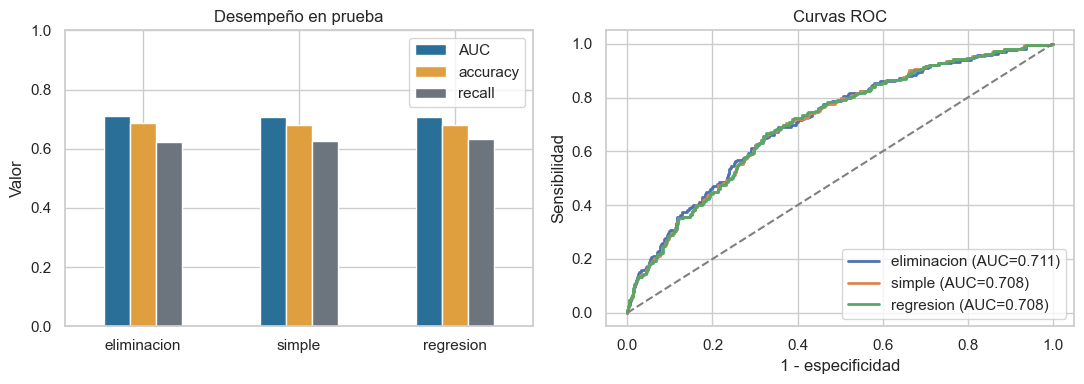

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metricas.plot(x='estrategia', y=['AUC', 'accuracy', 'recall'], kind='bar', ylim=(0, 1), ax=axes[0],
              color=['#2A6F97', '#E09F3E', '#6C757D'])
axes[0].set(title='Desempeño en prueba', xlabel='', ylabel='Valor')
axes[0].tick_params(axis='x', rotation=0)
for estrategia, y, p in curvas:
    fpr, tpr, _ = roc_curve(y, p)
    auc = metricas.loc[metricas['estrategia'] == estrategia, 'AUC'].iloc[0]
    axes[1].plot(fpr, tpr, lw=2, label=f'{estrategia} (AUC={auc:.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='0.5')
axes[1].set(title='Curvas ROC', xlabel='1 - especificidad', ylabel='Sensibilidad')
axes[1].legend()
fig.tight_layout()
plt.savefig(FIGURAS / 'p4_fig1_metricas_roc_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

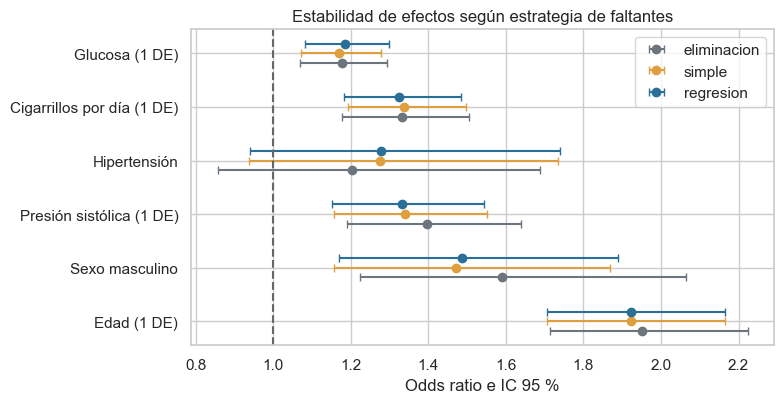

In [6]:
sin_constante = coeficientes.query("variable != 'const'").copy()
variables = sin_constante['variable'].unique().tolist()
estrategias = ['eliminacion', 'simple', 'regresion']
desplazamientos = {'eliminacion': -0.18, 'simple': 0.0, 'regresion': 0.18}
colores = {'eliminacion': '#6C757D', 'simple': '#E09F3E', 'regresion': '#2A6F97'}
fig, ax = plt.subplots(figsize=(8, max(4, 0.7 * len(variables))))
for i, variable in enumerate(variables):
    for estrategia in estrategias:
        fila = sin_constante.query('variable == @variable and estrategia == @estrategia').iloc[0]
        y = i + desplazamientos[estrategia]
        ax.errorbar(fila['odds_ratio'], y,
                    xerr=[[fila['odds_ratio']-fila['IC95_OR_inf']],
                          [fila['IC95_OR_sup']-fila['odds_ratio']]],
                    fmt='o', color=colores[estrategia], capsize=3, label=estrategia if i == 0 else None)
ax.axvline(1, color='0.4', linestyle='--')
etiquetas = [NOMBRES[v].split(' (')[0] + (' (1 DE)' if v in NUMERICAS else '') for v in variables]
ax.set_yticks(range(len(variables)), etiquetas)
ax.set(xlabel='Odds ratio e IC 95 %', title='Estabilidad de efectos según estrategia de faltantes')
ax.legend()
fig.tight_layout()
plt.savefig(FIGURAS / 'p4_fig2_or_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

## 4.2 Interpretación y recomendación

La estrategia de imputación casi no cambia el desempeño del modelo final. En prueba, el AUC va de 0,708 (simple y regresión) a 0,711 (eliminación) y el recall de 0,624 a 0,632. La comparación de eliminación debe leerse con cuidado: se evalúa sobre 1.111 filas de prueba y no sobre 1.272, así que parte de su diferencia es composición muestral. Simple y regresión sí se evalúan sobre exactamente las mismas filas y sus diferencias son mínimas (un caso detectado más con regresión).

Los cinco efectos significativos (edad, sexo, presión sistólica, cigarrillos y glucosa) mantienen signo y significación al 5 % en las tres estrategias. La hipertensión es no significativa en las tres (p entre 0,118 y 0,284), lo mismo que se observa en el bootstrap de la Parte 3, donde es el único parámetro inestable. Su efecto no depende de cómo se traten los faltantes: es débil una vez que se ajusta por presión sistólica y edad.

La eliminación tiene un costo concreto. Usa 2.547 filas de entrenamiento en vez de 2.968, pierde 87 casos de CHD en total (59 en entrenamiento y 28 en prueba), ensancha los IC de los coeficientes en promedio un 9 % (0,369 frente a 0,340) y sube el OR de sexo de 1,49 a 1,59 y el de sistólica de 1,33 a 1,40. Además supone que los faltantes son MCAR, algo más fuerte que el supuesto MAR de la Parte 1. La imputación simple con mediana comprime la variabilidad de la glucosa, como anticipó la S2, aunque eso no alcanza a mover los OR.

Recomendación: mantener la imputación por regresión, que conserva toda la muestra y las correlaciones validadas en la S2, y reportar la eliminación como análisis de sensibilidad. Las conclusiones del modelo final son robustas a la estrategia de faltantes.